# Determinan TFP

ditulis: tim PSE Atha Bintang Wahyu M. | PSE UGM

--> Sampel `Determinan TFP Provinsi.do`: 34 provinsi × 2017–2024.
--> Residual DRS `logtfp_it`, residual CRS `logtfp_it_crs`.
--> Peta pilar: rata-rata z, polaritas diseragamkan (APK dan Gini dibalik).
--> Heatmap korelasi: tanda z seperti di regresi.
--> Queen = daftar sisi `eval2.do`.
--> W pulau = provinsi lain di pulau yang sama.
--> Gambar: `01 Data/TFP/output/determinan/viz/`.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

def find_root():
    here = Path.cwd().resolve()
    for cand in [here, *here.parents]:
        if (cand / "02 Code" / "BKPM" / "2026bkpm.Rproj").exists():
            return cand
    return Path("/Users/athamawardi/Desktop/Research-Projects/RDSI_Kemeninves")

ROOT = find_root()
NAVY, CYAN, RED, TEAL, CREAM, PINK, GRAY = (
    "#0E2440", "#5DD0E6", "#D9042B", "#46A694", "#F2E6CE", "#F2509C", "#797F8C",
)
PULAU_ORDER = ["Sumatera", "Jawa", "Bali-Nusra", "Kalimantan", "Sulawesi", "Maluku-Papua"]
PULAU_FILL = {
    "Sumatera": CREAM, "Jawa": PINK, "Bali-Nusra": RED,
    "Kalimantan": "#062E4C", "Sulawesi": "#30726A", "Maluku-Papua": TEAL,
}
PULAU_INK = {
    "Sumatera": "#8A6A32", "Jawa": PINK, "Bali-Nusra": RED,
    "Kalimantan": "#062E4C", "Sulawesi": "#30726A", "Maluku-Papua": TEAL,
}
PILAR_COLOR = {
    "pendidikan": NAVY, "equity": TEAL, "institusi": "#062E4C",
    "konektivitas": CYAN, "lingkungan": "#30726A", "keamanan": GRAY,
}
LISA_COLOR = {"HH": NAVY, "HL": CYAN, "LH": CREAM, "LL": RED}
SHORT = {
    11: "Aceh", 12: "Sumut", 13: "Sumbar", 14: "Riau", 15: "Jambi",
    16: "Sumsel", 17: "Bengkulu", 18: "Lampung", 19: "Babel", 21: "Kepri",
    31: "Jakarta", 32: "Jabar", 33: "Jateng", 34: "DIY", 35: "Jatim", 36: "Banten",
    51: "Bali", 52: "NTB", 53: "NTT",
    61: "Kalbar", 62: "Kalteng", 63: "Kalsel", 64: "Kaltim", 65: "Kaltara",
    71: "Sulut", 72: "Sulteng", 73: "Sulsel", 74: "Sultra", 75: "Gorontalo", 76: "Sulbar",
    81: "Maluku", 82: "Malut", 91: "Papua Barat", 94: "Papua",
}
PULAU_OF = {}
for code, pulau in {
    **{c: "Sumatera" for c in [11, 12, 13, 14, 15, 16, 17, 18, 19, 21]},
    **{c: "Jawa" for c in [31, 32, 33, 34, 35, 36]},
    **{c: "Bali-Nusra" for c in [51, 52, 53]},
    **{c: "Kalimantan" for c in [61, 62, 63, 64, 65]},
    **{c: "Sulawesi" for c in [71, 72, 73, 74, 75, 76]},
    **{c: "Maluku-Papua" for c in [81, 82, 91, 94]},
}.items():
    PULAU_OF[code] = pulau
NAME2CODE = {
    "Aceh": 11, "SumateraUtara": 12, "SumateraBarat": 13, "Riau": 14,
    "Jambi": 15, "SumateraSelatan": 16, "Bengkulu": 17, "Lampung": 18,
    "BangkaBelitung": 19, "KepulauanRiau": 21, "JakartaRaya": 31,
    "JawaBarat": 32, "JawaTengah": 33, "Yogyakarta": 34, "JawaTimur": 35,
    "Banten": 36, "Bali": 51, "NusaTenggaraBarat": 52, "NusaTenggaraTimur": 53,
    "KalimantanBarat": 61, "KalimantanTengah": 62, "KalimantanSelatan": 63,
    "KalimantanTimur": 64, "KalimantanUtara": 65, "SulawesiUtara": 71,
    "SulawesiTengah": 72, "SulawesiSelatan": 73, "SulawesiTenggara": 74,
    "Gorontalo": 75, "SulawesiBarat": 76, "Maluku": 81, "MalukuUtara": 82,
    "PapuaBarat": 91, "Papua": 94,
}
# Sisi tak-berarah, daftar eval2.do.
QUEEN_PAIRS = [
    (11, 12), (12, 13), (13, 14), (13, 15), (13, 16), (14, 15), (14, 16), (14, 21),
    (15, 16), (15, 17), (16, 17), (16, 18), (16, 19), (17, 18),
    (31, 32), (31, 36), (32, 33), (32, 36), (33, 34), (33, 35), (35, 51),
    (51, 52), (52, 53),
    (61, 62), (61, 63), (62, 63), (62, 64), (63, 64), (64, 65),
    (71, 72), (71, 75), (71, 82), (72, 73), (72, 74), (72, 75), (72, 76), (73, 74), (73, 76),
    (81, 82), (81, 94), (91, 94),
]
ARCHI_PAIRS = {(14, 21), (16, 19)}  # se-pulau, tetapi dipisah laut
LAB = {
    "z_ln_lama_sekolah_mean": "lama sekolah",
    "z_ln_lama_sekolah_harapan": "harapan sekolah",
    "z_db_sd": "−APK SD", "z_db_smp": "−APK SMP", "z_db_sma": "−APK SMA", "z_db_kampus": "−APK kampus",
    "z_ln_p1": "−kedalaman miskin", "z_ln_ipm": "IPM", "z_gini": "Gini",
    "z_ln_upah_rata": "upah rata-rata", "z_ln_indeks_demokrasi": "IDI",
    "z_price": "−deflator", "z_ln_rasio_pad": "rasio PAD",
    "z_ln_pertumbuhan_pdrb_adhb": "pertumbuhan ADHB", "z_ln_apbd_belanja": "belanja APBD",
    "z_ln_jalan_mantap": "jalan mantap", "z_ln_kargo_udara": "kargo udara",
    "z_ln_kargo_kapal": "kargo kapal", "z_ln_kargo_kereta": "kargo kereta",
    "z_ln_penumpang_total": "penumpang", "z_ln_airport_logistik": "bandara logistik",
    "z_ln_airport_komersil": "bandara komersial",
    "z_ln_indeks_lingkungan": "IKLH", "z_ln_indeks_hijau": "indeks hijau", "z_ln_indeks_biru": "indeks biru",
    "z_ln_crime_risk": "−risiko kriminal", "z_ln_crime_rate": "−crime rate",
    "z_ln_apbd_serapan": "serapan",
    "Wq_pilar_pendidikan": "Wq pendidikan", "Wq_pilar_equity": "Wq equity",
    "Wq_pilar_institusi": "Wq institusi", "Wq_rasio_pad": "Wq rasio PAD",
    "Wq_ln_apbd_belanja": "Wq belanja", "Wi_rasio_pad": "Wi rasio PAD",
    "share_inv_padat_karya": "inv. padat karya", "share_inv_padat_modal": "inv. padat modal",
    "share_inv_primer": "inv. primer", "share_inv_sekunder": "inv. sekunder",
    "share_inv_C": "inv. industri", "share_tk_C": "TK industri",
    "d_dom_primer": "dominan primer", "d_dom_sekunder": "dominan sekunder",
    "share_inv_hijau_inv": "inv. hijau", "share_tk_ekstraktif": "TK ekstraktif",
    "share_inv_A": "inv. pertanian", "d_sawit": "sawit (p75)", "kantong_lemah": "kantong lemah",
}

plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "axes.edgecolor": GRAY,
    "axes.grid": True, "grid.color": "#E6E6E6", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "font.size": 10, "axes.titlesize": 12,
    "axes.titleweight": "medium", "axes.titlecolor": NAVY, "axes.labelcolor": NAVY,
    "xtick.color": NAVY, "ytick.color": NAVY, "text.color": NAVY,
    "axes.unicode_minus": False, "legend.frameon": False,
})

def save(fig, name):
    path = OUT / name
    fig.savefig(path, dpi=160, bbox_inches="tight", facecolor="white")
    print(path.relative_to(ROOT))
    plt.show()

def star(p):
    if p < 0.001:
        return "***"
    if p < 0.01:
        return "**"
    if p < 0.05:
        return "*"
    return ""

def row_std(A):
    A = np.asarray(A, float)
    s = A.sum(1, keepdims=True)
    s[s == 0] = 1.0
    return A / s

def moran_I(y, W):
    z = np.asarray(y, float)
    z = z - np.nanmean(z)
    den = float(z @ z)
    if den <= 0:
        return np.nan
    return float(z @ (W @ z) / den)

def moran_p(y, W, nperm=999, seed=11):
    rng = np.random.default_rng(seed)
    y = np.asarray(y, float)
    I0 = moran_I(y, W)
    hits = 0
    for _ in range(nperm):
        if abs(moran_I(rng.permutation(y), W)) >= abs(I0) - 1e-15:
            hits += 1
    return I0, (hits + 1) / (nperm + 1)

def edge_style(a, b):
    pair = tuple(sorted((int(a), int(b))))
    if PULAU_OF[pair[0]] != PULAU_OF[pair[1]]:
        return RED, "-"
    if pair in ARCHI_PAIRS:
        return "#8A6A32", "--"
    return NAVY, "-"

def ordered_codes():
    return [c for p in PULAU_ORDER for c in SHORT if PULAU_OF[c] == p]

def weights(codes):
    n = len(codes)
    idx = {c: i for i, c in enumerate(codes)}
    A = np.zeros((n, n))
    for a, b in QUEEN_PAIRS:
        i, j = idx[a], idx[b]
        A[i, j] = A[j, i] = 1.0
    Ai = np.zeros((n, n))
    for i, ci in enumerate(codes):
        for j, cj in enumerate(codes):
            if i != j and PULAU_OF[ci] == PULAU_OF[cj]:
                Ai[i, j] = 1.0
    return A, Ai, row_std(A), row_std(Ai)

def load_gdf(codes):
    import geopandas as gpd
    gadm = ROOT / "02 Code" / "TFP" / "docs" / "06 Review" / "assets" / "gadm41_IDN_1.json"
    g = gpd.read_file(gadm)[["NAME_1", "geometry"]]
    g["Code_Prov"] = g["NAME_1"].map(NAME2CODE)
    g = g.dropna(subset=["Code_Prov"])
    g["Code_Prov"] = g["Code_Prov"].astype(int)
    g = g.dissolve(by="Code_Prov", as_index=False)
    g = g.set_index("Code_Prov").reindex(codes).reset_index()
    if g["geometry"].isna().any():
        raise RuntimeError("GADM tidak memuat semua kode provinsi 34")
    g = g.to_crs(3857)
    g["geometry"] = g.geometry.simplify(2000, preserve_topology=True)
    g["Pulau"] = g["Code_Prov"].map(PULAU_OF)
    g["short"] = g["Code_Prov"].map(SHORT)
    return g

def choro(ax, gdf, col, title, center="zero"):
    s = gdf[col].astype(float)
    if center == "zero":
        v = np.nanmax(np.abs(s.to_numpy()))
        v = 1e-6 if not np.isfinite(v) or v == 0 else float(v)
        norm = mcolors.TwoSlopeNorm(vcenter=0, vmin=-v, vmax=v)
        cmap = "RdBu_r"
    elif center == "mean":
        mu = float(np.nanmean(s))
        v = max(mu - float(np.nanmin(s)), float(np.nanmax(s)) - mu, 1e-6)
        norm = mcolors.TwoSlopeNorm(vcenter=mu, vmin=mu - v, vmax=mu + v)
        cmap = "RdBu_r"
    else:
        norm = mcolors.Normalize(vmin=float(np.nanmin(s)), vmax=float(np.nanmax(s)))
        cmap = "PuBu"
    gdf.plot(column=col, ax=ax, cmap=cmap, norm=norm, linewidth=0.3,
             edgecolor="white", missing_kwds={"color": "#eeeeee"})
    sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
    sm.set_array([])
    cb = ax.figure.colorbar(sm, ax=ax, fraction=0.035, pad=0.02)
    cb.ax.tick_params(labelsize=7)
    ax.set_axis_off()
    ax.set_title(title, fontsize=11)
    ax.set_facecolor("#f6f5f2")

def style_map(ax):
    ax.set_axis_off()
    ax.set_facecolor("#f6f5f2")
    ax.grid(False)

def lisa_labels(y, wy):
    my, mw = np.median(y), np.median(wy)
    out = np.empty(len(y), dtype=object)
    for i, (a, b) in enumerate(zip(y, wy)):
        if a >= my and b >= mw:
            out[i] = "HH"
        elif a < my and b < mw:
            out[i] = "LL"
        elif a >= my and b < mw:
            out[i] = "HL"
        else:
            out[i] = "LH"
    return out

def draw_queen(ax, gdf, title):
    gdf.plot(ax=ax, color="#f4f1ea", edgecolor="white", linewidth=0.45)
    pts = gdf.set_index("Code_Prov").geometry.representative_point()
    for a, b in QUEEN_PAIRS:
        color, ls = edge_style(a, b)
        ax.plot([pts[a].x, pts[b].x], [pts[a].y, pts[b].y],
                color=color, ls=ls, lw=1.15, zorder=3, solid_capstyle="round")
    style_map(ax)
    ax.set_title(title)
    ax.legend(handles=[
        Line2D([0], [0], color=NAVY, lw=1.4, label="queen, darat"),
        Line2D([0], [0], color="#8A6A32", lw=1.4, ls="--", label="queen, laut se-pulau"),
        Line2D([0], [0], color=RED, lw=1.4, label="queen, antar-pulau"),
    ], loc="lower left", fontsize=8)

def draw_islands(ax, gdf, title):
    for p in PULAU_ORDER:
        gdf[gdf.Pulau == p].plot(ax=ax, color=PULAU_FILL[p], edgecolor="white", linewidth=0.45)
    style_map(ax)
    ax.set_title(title)
    ax.legend(handles=[Patch(facecolor=PULAU_FILL[p], edgecolor=GRAY, label=p) for p in PULAU_ORDER],
              loc="lower left", fontsize=8)

def block_lines(ax, codes):
    cuts = []
    start = 0
    for p in PULAU_ORDER:
        k = sum(PULAU_OF[c] == p for c in codes)
        cuts.append(start + k)
        start += k
    for c in cuts[:-1]:
        ax.axhline(c - 0.5, color=RED, lw=0.6)
        ax.axvline(c - 0.5, color=RED, lw=0.6)

OUT = ROOT / "01 Data" / "TFP" / "output" / "determinan" / "viz"
OUT.mkdir(parents=True, exist_ok=True)
GROUPS = {
    "pendidikan": ["z_ln_lama_sekolah_mean", "z_ln_lama_sekolah_harapan",
                   "z_db_sd", "z_db_smp", "z_db_sma", "z_db_kampus"],
    "equity": ["z_ln_p1", "z_ln_ipm", "z_gini", "z_ln_upah_rata", "z_ln_indeks_demokrasi"],
    "institusi": ["z_price", "z_ln_rasio_pad", "z_ln_pertumbuhan_pdrb_adhb", "z_ln_apbd_belanja"],
    "konektivitas": ["z_ln_jalan_mantap", "z_ln_kargo_udara", "z_ln_kargo_kapal", "z_ln_kargo_kereta",
                     "z_ln_penumpang_total", "z_ln_airport_logistik", "z_ln_airport_komersil"],
    "lingkungan": ["z_ln_indeks_lingkungan", "z_ln_indeks_hijau", "z_ln_indeks_biru"],
    "keamanan": ["z_ln_crime_risk", "z_ln_crime_rate"],
}
PETA = {
    "peta_pendidikan": {**{v: 1 for v in GROUPS["pendidikan"][:2]},
                        **{v: -1 for v in GROUPS["pendidikan"][2:]}},
    "peta_equity": {"z_ln_p1": 1, "z_ln_ipm": 1, "z_gini": -1,
                    "z_ln_upah_rata": 1, "z_ln_indeks_demokrasi": 1},
    "peta_institusi": {v: 1 for v in GROUPS["institusi"]},
    "peta_konektivitas": {v: 1 for v in GROUPS["konektivitas"]},
    "peta_lingkungan": {v: 1 for v in GROUPS["lingkungan"]},
    "peta_keamanan": {v: 1 for v in GROUPS["keamanan"]},
}
PETA_TITLE = {
    "logtfp_it": "Residual DRS", "logtfp_it_crs": "Residual CRS",
    "peta_pendidikan": "Pendidikan", "peta_equity": "Equity",
    "peta_institusi": "Institusi", "peta_konektivitas": "Konektivitas",
    "peta_lingkungan": "Lingkungan", "peta_keamanan": "Keamanan",
}

d = pd.read_stata(ROOT / "01 Data" / "TFP" / "output" / "determinan" / "Determinan TFP Provinsi 2017-2024.dta")
d["Code_Prov"] = d["Code_Prov"].astype(int)
d["Year"] = d["Year"].astype(int)
d["Pulau"] = d["Code_Prov"].map(PULAU_OF)
d["short"] = d["Code_Prov"].map(SHORT)
for name, spec in PETA.items():
    d[name] = sum(sign * d[v] for v, sign in spec.items()) / len(spec)

codes = ordered_codes()
A, Ai, Wq, Wi = weights(codes)
gdf = load_gdf(codes)
X = [v for vs in GROUPS.values() for v in vs]
print(f"{d.Code_Prov.nunique()} provinsi, {d.Year.min()}–{d.Year.max()}, N = {len(d)}")


34 provinsi, 2017–2024, N = 272


## Sebaran, jalur waktu, peringkat


findfont: Failed to find font weight medium for DejaVu Sans, now using 400.
01 Data/TFP/output/determinan/viz/det_sebaran_z.png
01 Data/TFP/output/determinan/viz/det_jalur_pulau.png
01 Data/TFP/output/determinan/viz/det_box_crs.png
01 Data/TFP/output/determinan/viz/det_peringkat_crs.png
01 Data/TFP/output/determinan/viz/det_delta_crs.png


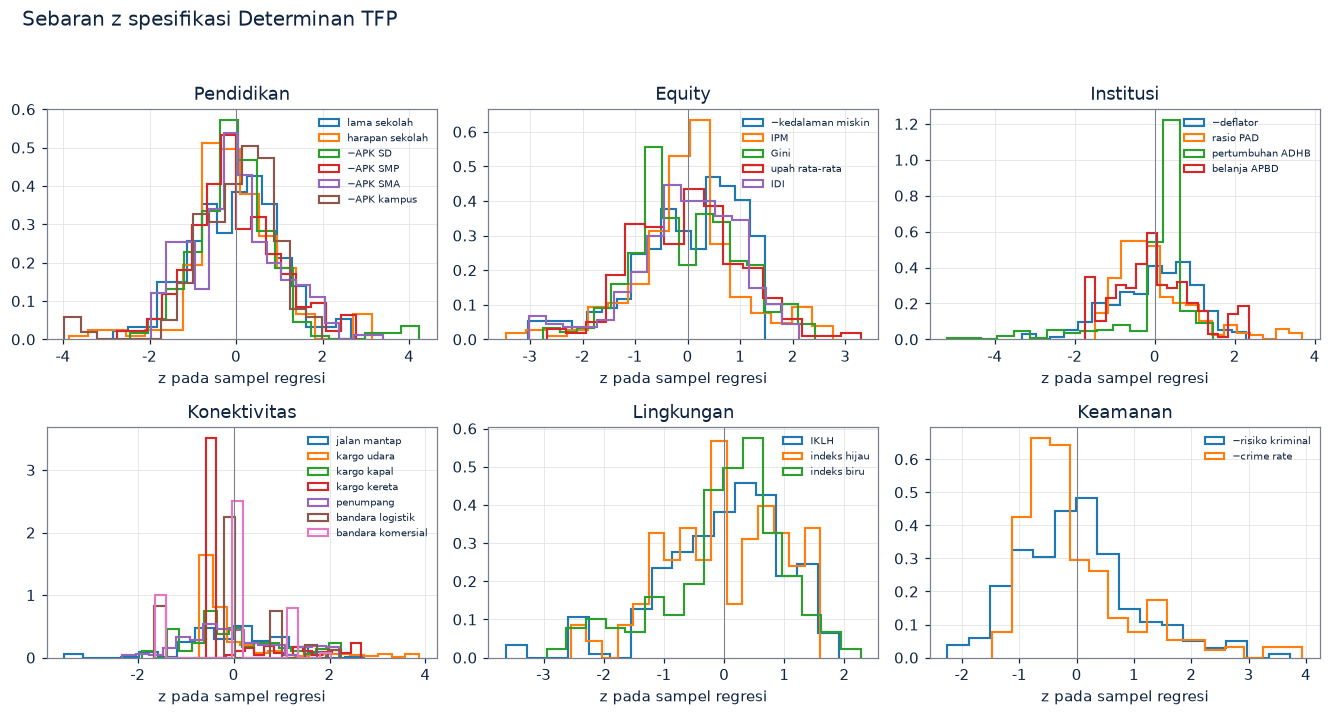

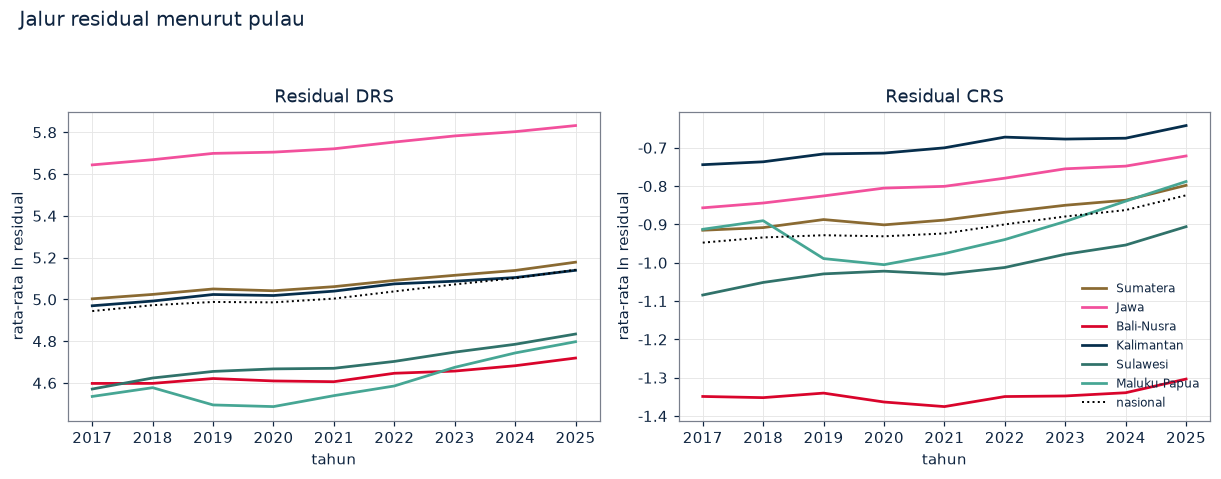

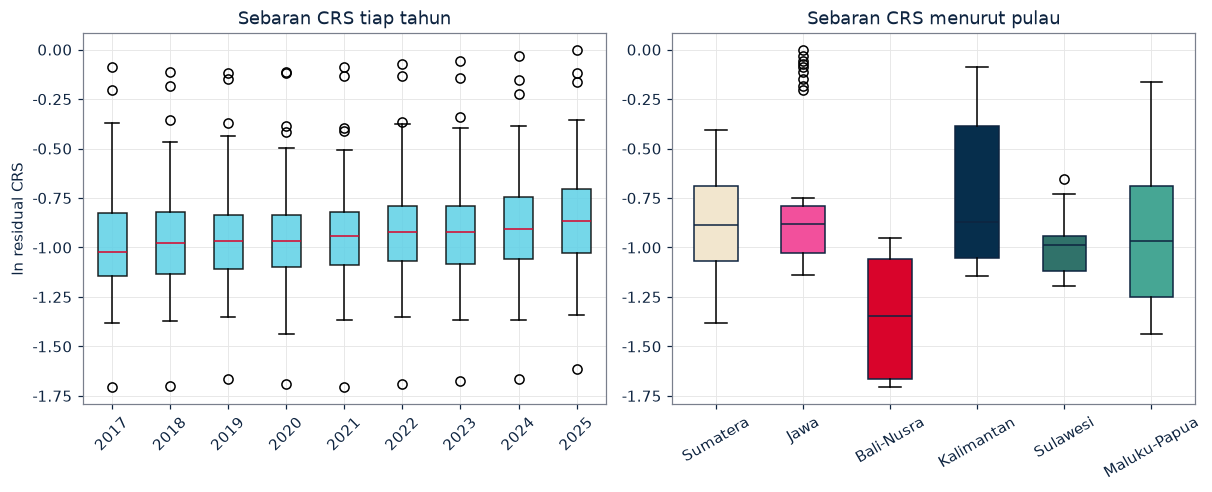

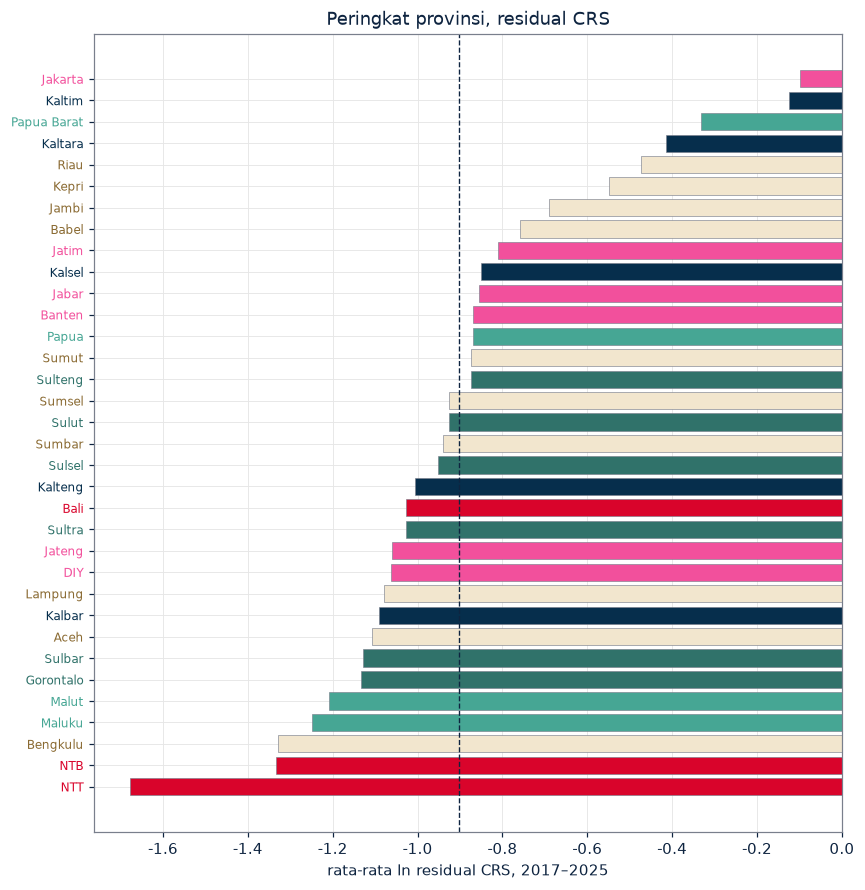

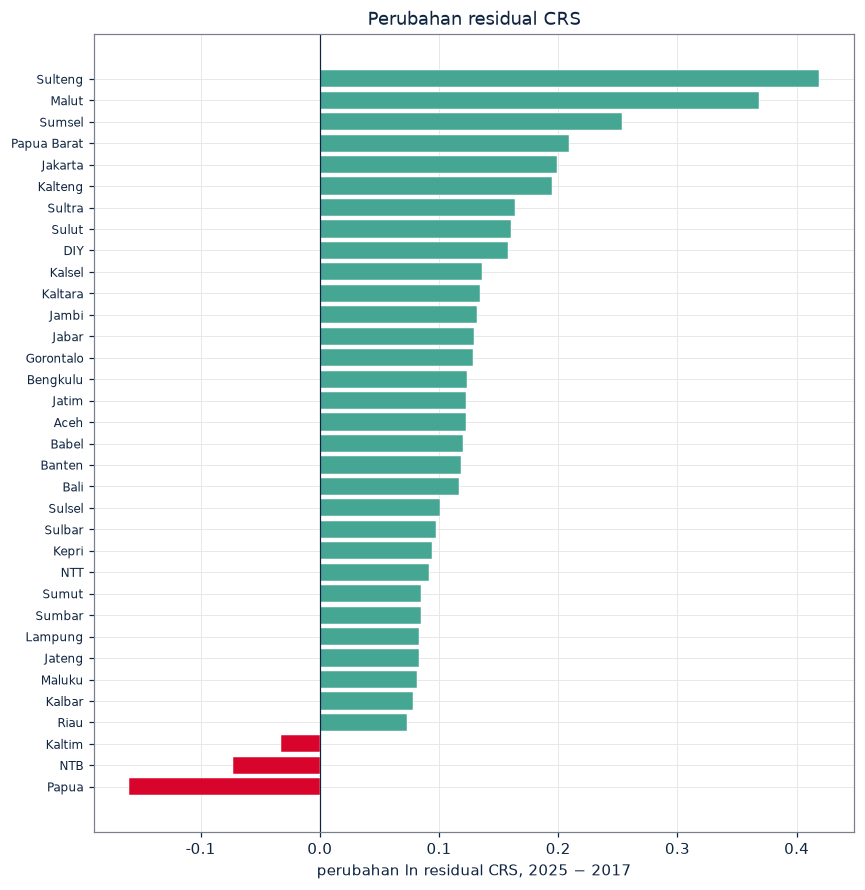

In [2]:
ink = [PILAR_COLOR[g] for g, vs in GROUPS.items() for _ in vs]
fig, axes = plt.subplots(2, 3, figsize=(12.2, 6.6), sharey=False)
for ax, (gname, vs) in zip(axes.ravel(), GROUPS.items()):
    for i, v in enumerate(vs):
        ax.hist(d[v], bins=16, density=True, histtype="step", lw=1.4,
                color=plt.get_cmap("tab10")(i), label=LAB.get(v, v))
    ax.axvline(0, color=GRAY, lw=0.7)
    ax.set_title(gname.capitalize())
    ax.legend(fontsize=6.5, loc="upper right")
    ax.set_xlabel("z pada sampel regresi")
fig.suptitle("Sebaran z spesifikasi Determinan TFP", x=0.02, ha="left", fontsize=13, color=NAVY)
fig.tight_layout(rect=(0, 0, 1, 0.95))
save(fig, "det_sebaran_z.png")

ext = pd.read_excel(ROOT / "01 Data/TFP/output/eval/eval_panel_2017_2025.xlsx", sheet_name="panel")
ext = ext[ext.Year == 2025].copy()
ext["Code_Prov"] = ext["Code_Prov"].astype(int)
ext["Year"] = ext["Year"].astype(int)
ext["Pulau"] = ext["Code_Prov"].map(PULAU_OF)
ext["short"] = ext["Code_Prov"].map(SHORT)
keep = ["Code_Prov", "Year", "Pulau", "short", "logtfp_it", "logtfp_it_crs"] + [v for vs in GROUPS.values() for v in vs]
show = pd.concat([d[keep], ext[keep]], ignore_index=True)
for name, spec in PETA.items():
    show[name] = sum(sign * show[v] for v, sign in spec.items()) / len(spec)

fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.4))
for ax, col, title in zip(axes, ["logtfp_it", "logtfp_it_crs"], ["Residual DRS", "Residual CRS"]):
    for p in PULAU_ORDER:
        s = show[show.Pulau == p].groupby("Year")[col].mean()
        ax.plot(s.index, s.values, color=PULAU_INK[p], lw=1.8, label=p)
    nat = show.groupby("Year")[col].mean()
    ax.plot(nat.index, nat.values, color="black", lw=1.3, ls=":", label="nasional")
    ax.set_title(title)
    ax.set_xlabel("tahun")
    ax.set_ylabel("rata-rata ln residual")
axes[1].legend(fontsize=8, loc="best")
fig.suptitle("Jalur residual menurut pulau", x=0.02, ha="left", fontsize=13, color=NAVY)
fig.tight_layout(rect=(0, 0, 1, 0.93))
save(fig, "det_jalur_pulau.png")

fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.6))
for ax, col, title in zip(axes, ["logtfp_it_crs", "logtfp_it_crs"], ["CRS menurut tahun", "CRS menurut pulau"]):
    pass
bp = axes[0].boxplot(
    [show.loc[show.Year == y, "logtfp_it_crs"] for y in range(2017, 2026)],
    tick_labels=list(range(2017, 2026)), patch_artist=True, medianprops={"color": RED},
)
for box in bp["boxes"]:
    box.set_facecolor(CYAN)
    box.set_alpha(0.85)
axes[0].set_title("Sebaran CRS tiap tahun")
axes[0].tick_params(axis="x", labelrotation=45)
axes[0].set_ylabel("ln residual CRS")
bp = axes[1].boxplot(
    [show.loc[show.Pulau == p, "logtfp_it_crs"] for p in PULAU_ORDER],
    tick_labels=PULAU_ORDER, patch_artist=True, medianprops={"color": NAVY},
)
for box, p in zip(bp["boxes"], PULAU_ORDER):
    box.set_facecolor(PULAU_FILL[p])
    box.set_edgecolor(NAVY)
axes[1].set_title("Sebaran CRS menurut pulau")
axes[1].tick_params(axis="x", labelrotation=30)
fig.tight_layout()
save(fig, "det_box_crs.png")

mean = show.groupby(["Code_Prov", "short", "Pulau"], as_index=False)["logtfp_it_crs"].mean()
mean = mean.sort_values("logtfp_it_crs")
fig, ax = plt.subplots(figsize=(8, 8.2))
ax.barh(mean["short"], mean["logtfp_it_crs"],
        color=[PULAU_FILL[p] for p in mean["Pulau"]], edgecolor=GRAY, linewidth=0.4)
ax.axvline(mean["logtfp_it_crs"].mean(), color=NAVY, ls="--", lw=0.9)
ax.set_xlabel("rata-rata ln residual CRS, 2017–2025")
ax.set_title("Peringkat provinsi, residual CRS")
ax.tick_params(axis="y", labelsize=8)
for lab, p in zip(ax.get_yticklabels(), mean["Pulau"]):
    lab.set_color(PULAU_INK[p])
fig.tight_layout()
save(fig, "det_peringkat_crs.png")

wide = show.pivot(index="Code_Prov", columns="Year", values="logtfp_it_crs")
delta = (wide[2025] - wide[2017]).rename("delta")
delta = delta.reset_index()
delta["short"] = delta["Code_Prov"].map(SHORT)
delta["Pulau"] = delta["Code_Prov"].map(PULAU_OF)
delta = delta.sort_values("delta")
fig, ax = plt.subplots(figsize=(8, 8.2))
colors = [TEAL if v >= 0 else RED for v in delta["delta"]]
ax.barh(delta["short"], delta["delta"], color=colors, edgecolor="white", linewidth=0.3)
ax.axvline(0, color=NAVY, lw=0.8)
ax.set_xlabel("perubahan ln residual CRS, 2025 − 2017")
ax.set_title("Perubahan residual CRS")
ax.tick_params(axis="y", labelsize=8)
fig.tight_layout()
save(fig, "det_delta_crs.png")


## Korelasi z dan upah tiga kelompok
--> Kelompok upah di akhir `Determinan TFP Provinsi.do`: primer (pertanian, tambang), sekunder (industri, listrik, air, konstruksi), tersier (sisanya).


01 Data/TFP/output/determinan/viz/det_korelasi_z.png
01 Data/TFP/output/determinan/viz/det_upah_kelompok.png


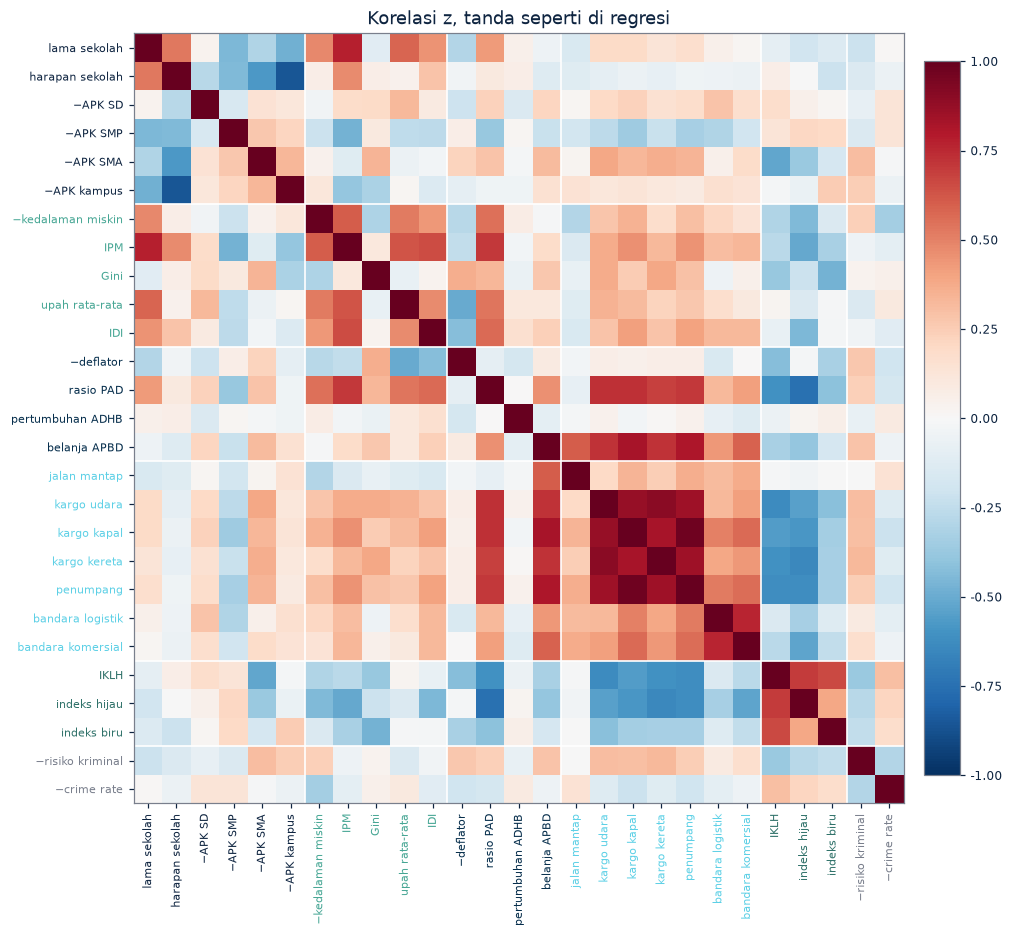

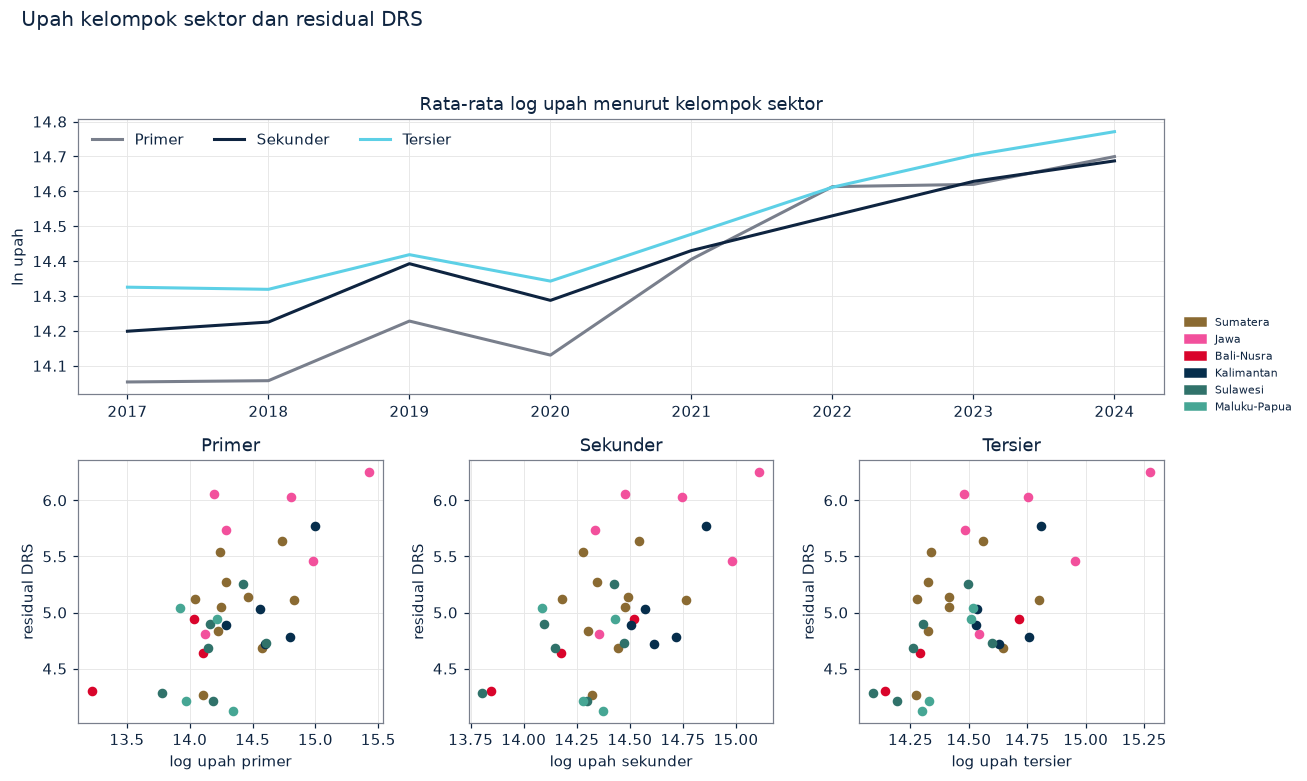

In [3]:
labels = [LAB.get(v, v) for v in X]
corr = d[X].corr()
fig, ax = plt.subplots(figsize=(10.2, 8.6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1, origin="upper")
ax.set_xticks(range(len(X)))
ax.set_yticks(range(len(X)))
ax.set_xticklabels(labels, rotation=90, fontsize=7)
ax.set_yticklabels(labels, fontsize=7)
for tick, v in zip(ax.get_xticklabels(), X):
    gname = next(g for g, vs in GROUPS.items() if v in vs)
    tick.set_color(PILAR_COLOR[gname])
for tick, v in zip(ax.get_yticklabels(), X):
    gname = next(g for g, vs in GROUPS.items() if v in vs)
    tick.set_color(PILAR_COLOR[gname])
cut = 0
for vs in GROUPS.values():
    cut += len(vs)
    if cut < len(X):
        ax.axhline(cut - 0.5, color="white", lw=1.1)
        ax.axvline(cut - 0.5, color="white", lw=1.1)
fig.colorbar(im, ax=ax, fraction=0.035, pad=0.02).ax.tick_params(labelsize=8)
ax.set_title("Korelasi z, tanda seperti di regresi")
ax.grid(False)
fig.tight_layout()
save(fig, "det_korelasi_z.png")

fig = plt.figure(figsize=(12, 7.2))
gs = fig.add_gridspec(2, 3, height_ratios=[1.05, 1])
ax0 = fig.add_subplot(gs[0, :])
wage_cols = [("ln_upah_primer", "Primer", GRAY),
             ("ln_upah_sekunder", "Sekunder", NAVY),
             ("ln_upah_tersier", "Tersier", CYAN)]
for col, lab, color in wage_cols:
    s = d.groupby("Year")[col].mean()
    ax0.plot(s.index, s.values, color=color, lw=2, label=lab)
ax0.set_title("Rata-rata log upah menurut kelompok sektor")
ax0.set_ylabel("ln upah")
ax0.legend(ncol=3)
pm = d.groupby(["Code_Prov", "Pulau"], as_index=False)[
    ["ln_upah_primer", "ln_upah_sekunder", "ln_upah_tersier", "logtfp_it"]
].mean()
for ax, (col, lab, _) in zip([fig.add_subplot(gs[1, i]) for i in range(3)], wage_cols):
    for p in PULAU_ORDER:
        sub = pm[pm.Pulau == p]
        ax.scatter(sub[col], sub["logtfp_it"], s=28, color=PULAU_INK[p], label=p, zorder=3)
    ax.set_xlabel(f"log upah {lab.lower()}")
    ax.set_ylabel("residual DRS")
    ax.set_title(lab)
fig.legend(handles=[Patch(color=PULAU_INK[p], label=p) for p in PULAU_ORDER],
           loc="lower right", bbox_to_anchor=(0.99, 0.46), fontsize=7, ncol=1)
fig.suptitle("Upah kelompok sektor dan residual DRS", x=0.02, ha="left", fontsize=13, color=NAVY)
fig.tight_layout(rect=(0, 0, 0.90, 0.94))
save(fig, "det_upah_kelompok.png")


## Kontiguitas queen dan pulau
--> Matriks kiri jarang (hanya tetangga daftar queen).
--> Matriks kanan blok penuh: di dalam Sumatera, setiap provinsi bertetangga dengan sembilan provinsi lain, termasuk yang tidak berbagi batas.


01 Data/TFP/output/determinan/viz/det_matriks_W.png
01 Data/TFP/output/determinan/viz/det_peta_kontiguitas.png
01 Data/TFP/output/determinan/viz/det_derajat_tetangga.png


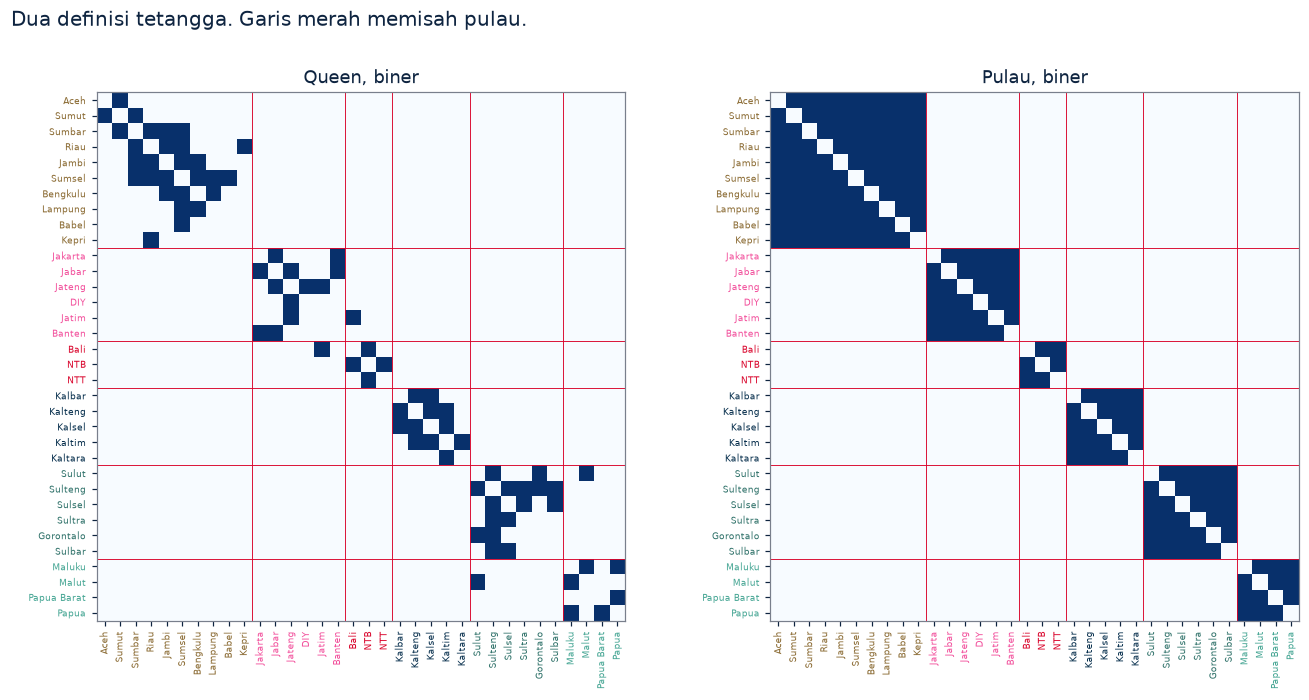

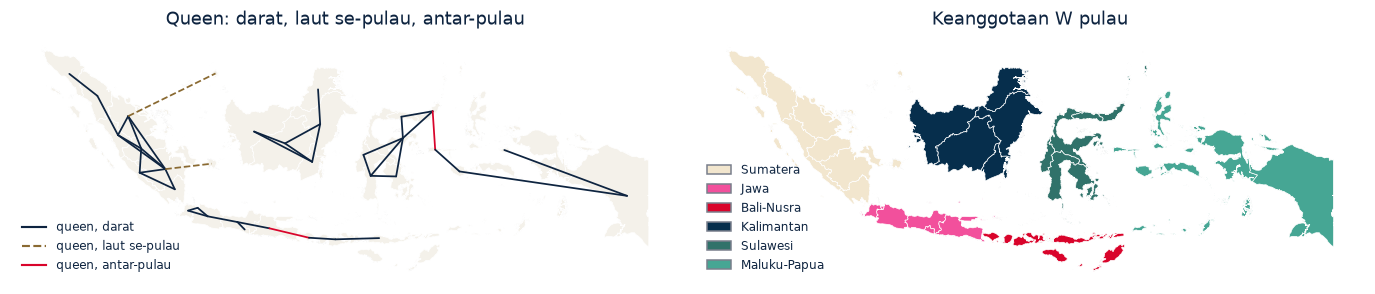

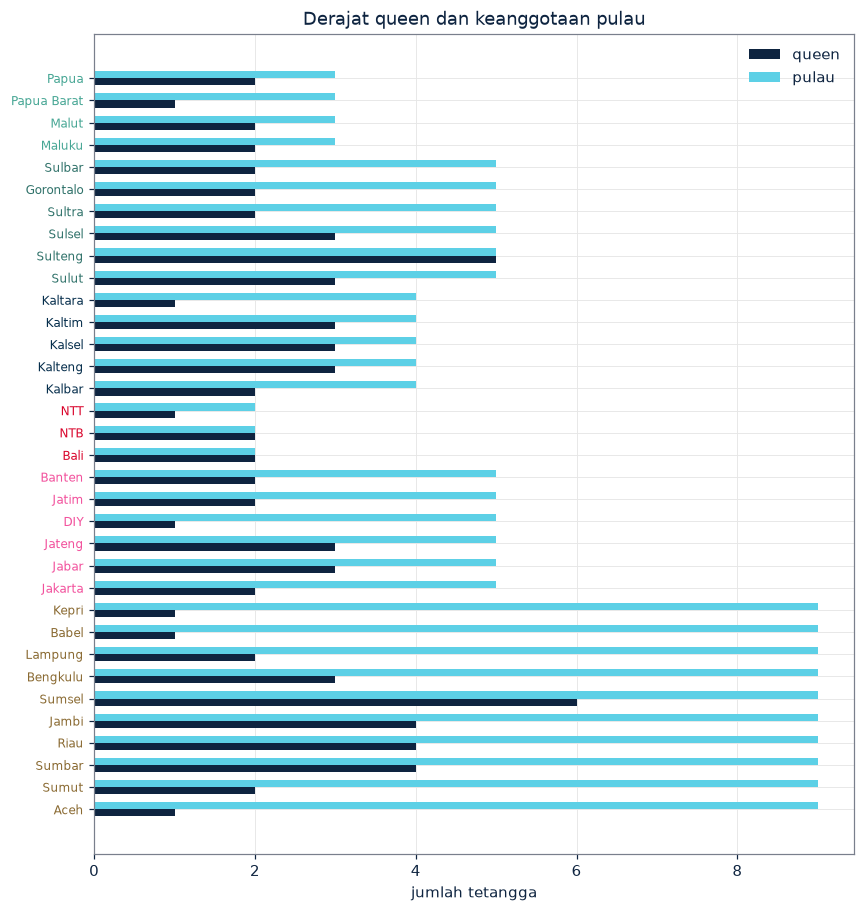

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12.4, 6.2))
shorts = [SHORT[c] for c in codes]
for ax, M, title in zip(axes, [A, Ai], ["Queen, biner", "Pulau, biner"]):
    ax.imshow(M, cmap="Blues", vmin=0, vmax=1, origin="upper")
    ax.set_xticks(range(len(codes)))
    ax.set_yticks(range(len(codes)))
    ax.set_xticklabels(shorts, rotation=90, fontsize=6)
    ax.set_yticklabels(shorts, fontsize=6)
    for tick, c in zip(ax.get_xticklabels(), codes):
        tick.set_color(PULAU_INK[PULAU_OF[c]])
    for tick, c in zip(ax.get_yticklabels(), codes):
        tick.set_color(PULAU_INK[PULAU_OF[c]])
    block_lines(ax, codes)
    ax.set_title(title)
    ax.grid(False)
fig.suptitle("Dua definisi tetangga. Garis merah memisah pulau.", x=0.02, ha="left", fontsize=13, color=NAVY)
fig.tight_layout(rect=(0, 0, 1, 0.94))
save(fig, "det_matriks_W.png")

fig, axes = plt.subplots(1, 2, figsize=(12.6, 6.8))
draw_queen(axes[0], gdf, "Queen: darat, laut se-pulau, antar-pulau")
draw_islands(axes[1], gdf, "Keanggotaan W pulau")
fig.tight_layout()
save(fig, "det_peta_kontiguitas.png")

deg_q = A.sum(1)
deg_i = Ai.sum(1)
order = np.argsort(np.array([PULAU_ORDER.index(PULAU_OF[c]) * 100 + c for c in codes]))
y = np.arange(len(codes))
fig, ax = plt.subplots(figsize=(8, 8.4))
ax.barh(y - 0.16, deg_q[order], height=0.32, color=NAVY, label="queen")
ax.barh(y + 0.16, deg_i[order], height=0.32, color=CYAN, label="pulau")
ax.set_yticks(y)
ax.set_yticklabels([SHORT[codes[i]] for i in order], fontsize=8)
for lab, i in zip(ax.get_yticklabels(), order):
    lab.set_color(PULAU_INK[PULAU_OF[codes[i]]])
ax.set_xlabel("jumlah tetangga")
ax.set_title("Derajat queen dan keanggotaan pulau")
ax.legend()
fig.tight_layout()
save(fig, "det_derajat_tetangga.png")


## Peta level dan perubahan


findfont: Failed to find font weight medium for DejaVu Sans, now using 400.
01 Data/TFP/output/determinan/viz/det_peta_level.png
01 Data/TFP/output/determinan/viz/det_peta_delta.png


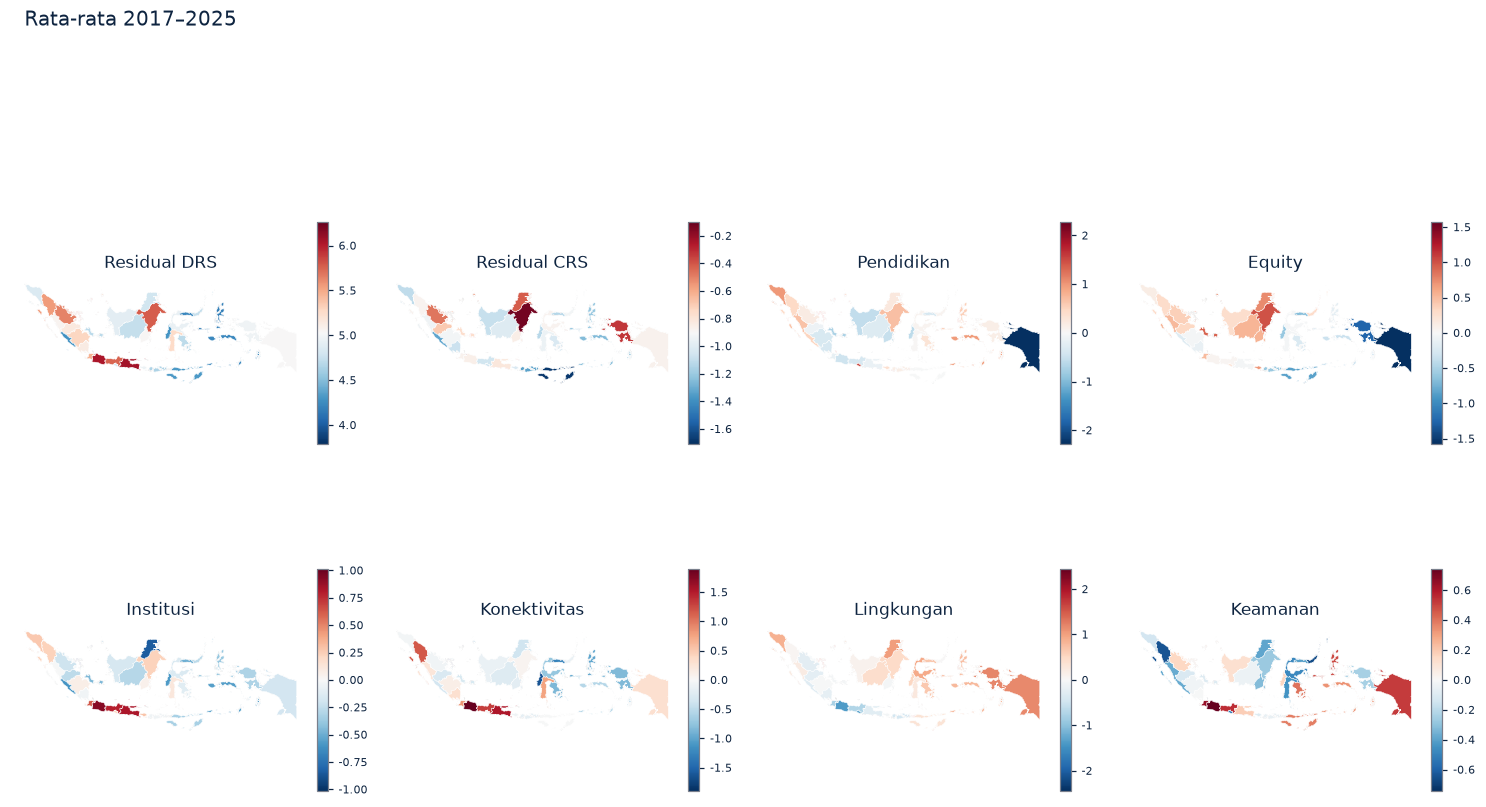

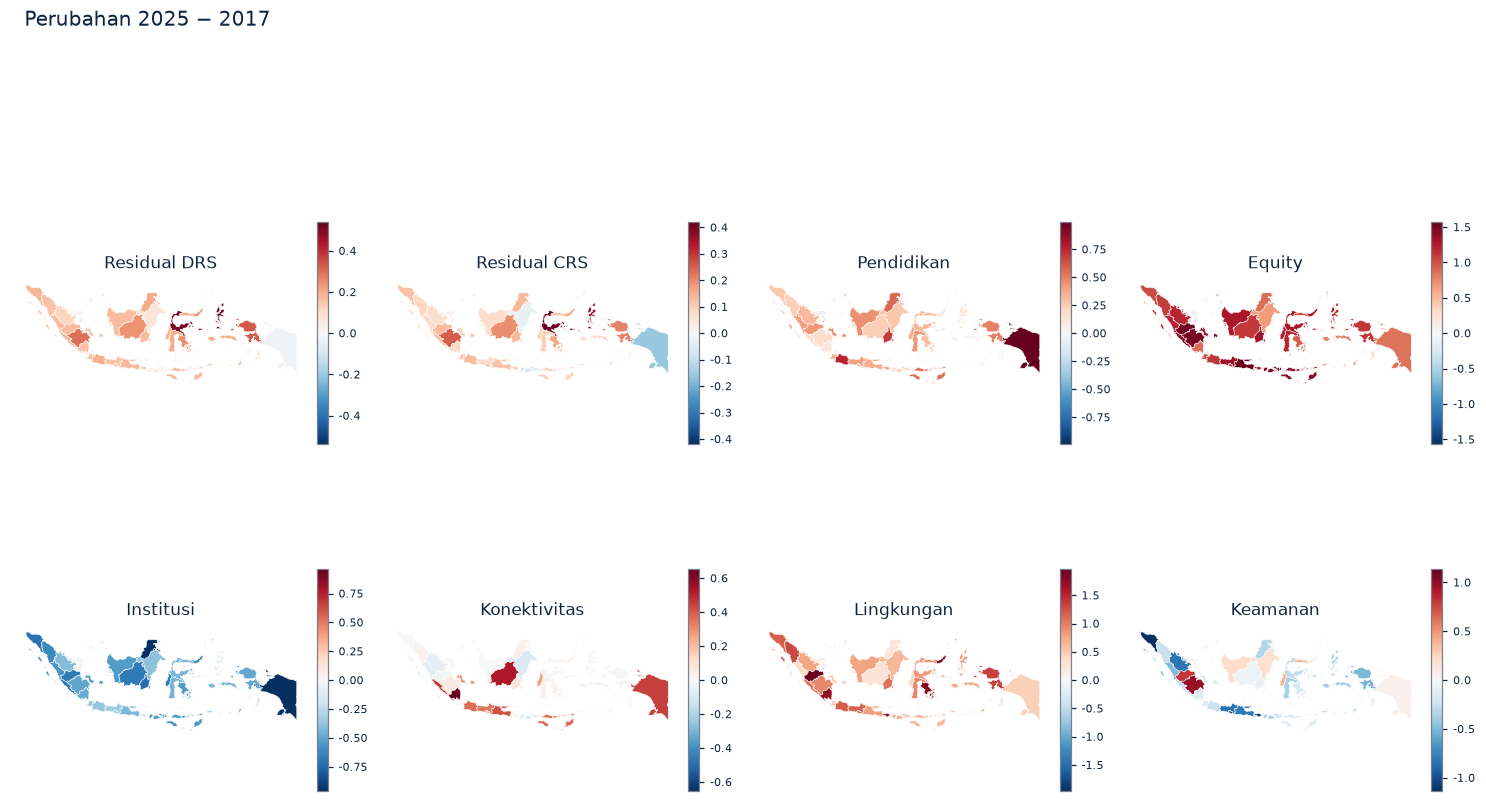

In [5]:
def attach_mean(col):
    gdf[col] = gdf["Code_Prov"].map(show.groupby("Code_Prov")[col].mean())

def attach_delta(col):
    wide = show.pivot(index="Code_Prov", columns="Year", values=col)
    gdf[col + "_d"] = gdf["Code_Prov"].map(wide[2025] - wide[2017])

level_cols = ["logtfp_it", "logtfp_it_crs", *PETA.keys()]
for col in level_cols:
    attach_mean(col)
    attach_delta(col)

fig, axes = plt.subplots(2, 4, figsize=(13.6, 8.6))
for ax, col in zip(axes.ravel(), level_cols):
    center = "mean" if col.startswith("logtfp") else "zero"
    choro(ax, gdf, col, PETA_TITLE[col], center=center)
fig.suptitle("Rata-rata 2017–2025", x=0.02, ha="left", fontsize=13, color=NAVY)
fig.tight_layout(rect=(0, 0, 1, 0.95))
save(fig, "det_peta_level.png")

fig, axes = plt.subplots(2, 4, figsize=(13.6, 8.6))
for ax, col in zip(axes.ravel(), level_cols):
    choro(ax, gdf, col + "_d", PETA_TITLE[col], center="zero")
fig.suptitle("Perubahan 2025 − 2017", x=0.02, ha="left", fontsize=13, color=NAVY)
fig.tight_layout(rect=(0, 0, 1, 0.95))
save(fig, "det_peta_delta.png")


## Moran dan kuadran median
--> I = z′Wz / z′z pada rata-rata provinsi (N = 34), W distandardisasi baris.
--> Bintang dari 999 permutasi.
--> Warna scatter = pulau.
--> Garis silang = median, sama seperti kuadran di peta (HH tinggi dikelilingi tinggi, LL sebaliknya).
--> I pada W pulau memakai rata-rata provinsi, N = 34.


01 Data/TFP/output/determinan/viz/det_moran_batang.png
01 Data/TFP/output/determinan/viz/det_moran_scatter.png
01 Data/TFP/output/determinan/viz/det_lisa.png


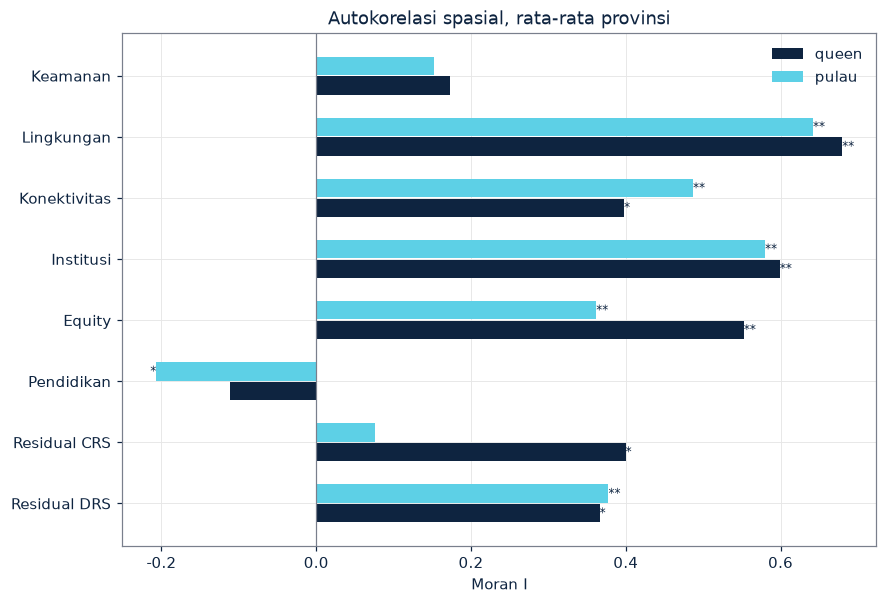

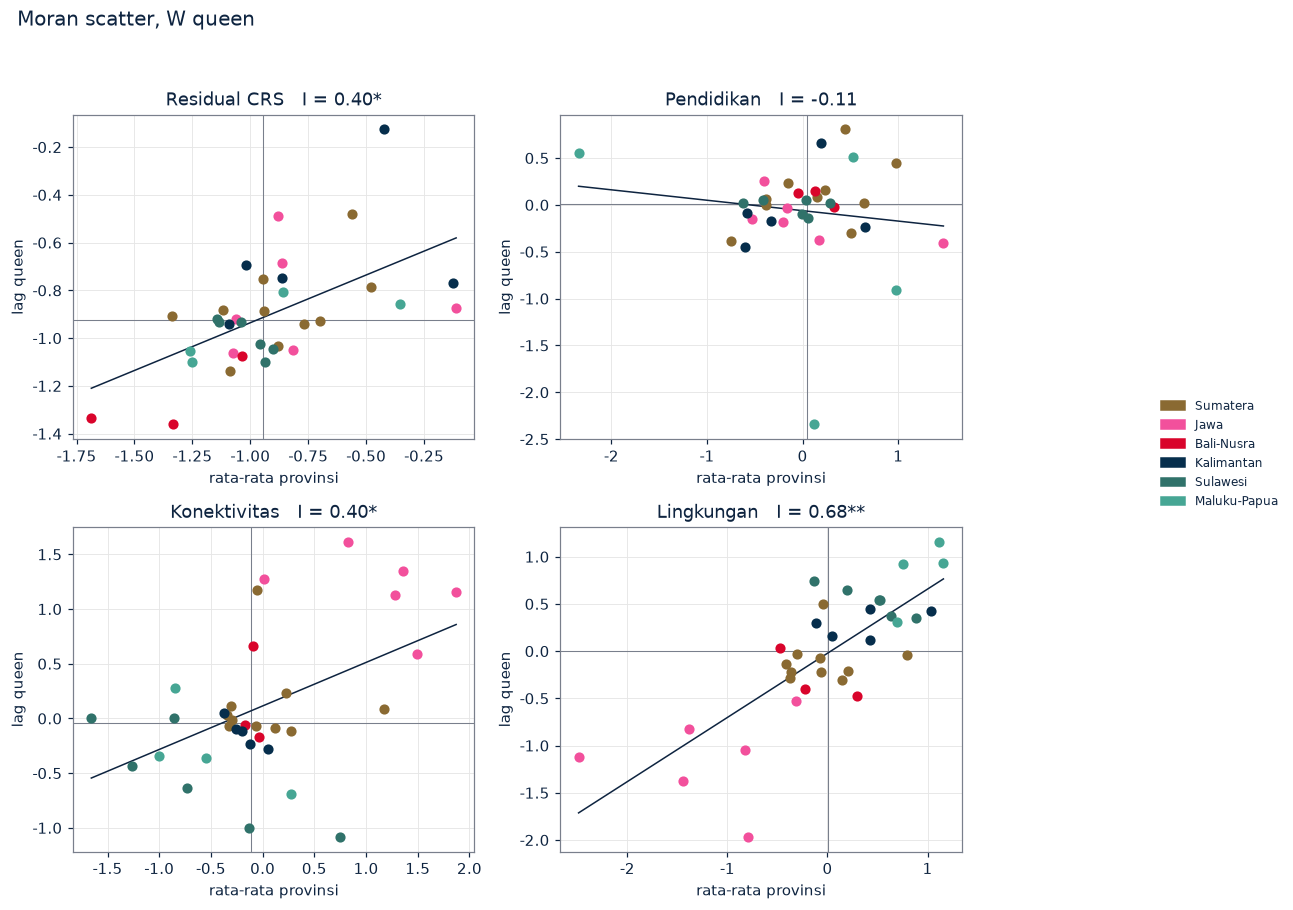

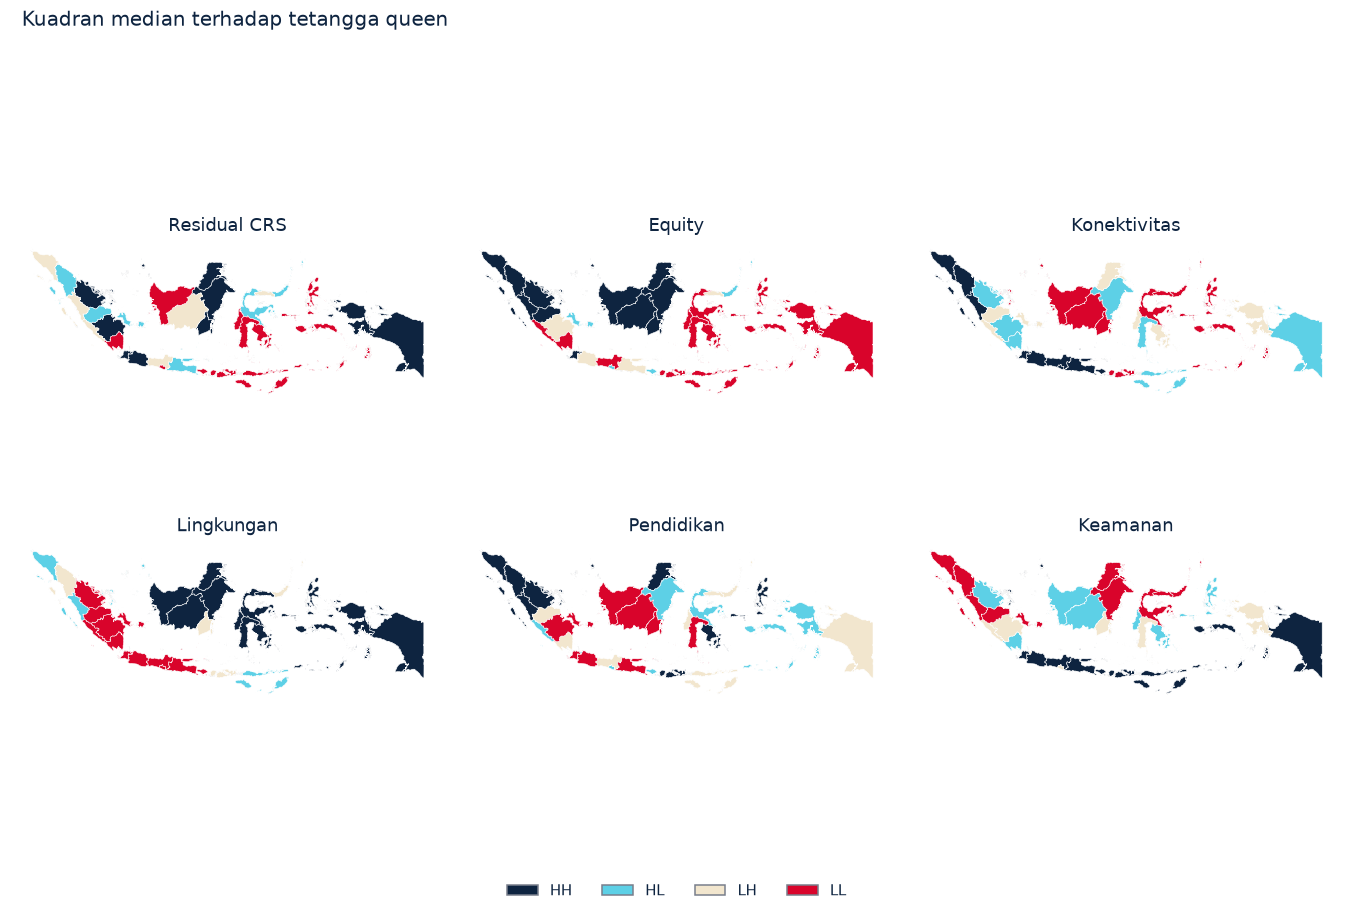

In [6]:
rng_vars = level_cols
rows = []
for col in rng_vars:
    y = d.groupby("Code_Prov")[col].mean().reindex(codes).to_numpy()
    for name, W in [("queen", Wq), ("pulau", Wi)]:
        I, p = moran_p(y, W)
        rows.append({"var": col, "W": name, "I": I, "p": p})
mor = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(8.2, 5.6))
ypos = np.arange(len(rng_vars))
for shift, wname, color in [(-0.16, "queen", NAVY), (0.16, "pulau", CYAN)]:
    sub = mor[mor.W == wname].set_index("var").loc[rng_vars]
    ax.barh(ypos + shift, sub["I"], height=0.3, color=color, label=wname)
    for yi, (I, p) in zip(ypos + shift, zip(sub["I"], sub["p"])):
        if star(p):
            ax.text(I, yi, star(p), va="center", ha="left" if I >= 0 else "right", fontsize=8, color=NAVY)
ax.set_yticks(ypos)
ax.set_yticklabels([PETA_TITLE[v] for v in rng_vars])
ax.axvline(0, color=GRAY, lw=0.8)
ax.set_xlabel("Moran I")
ax.set_title("Autokorelasi spasial, rata-rata provinsi")
ax.legend()
fig.tight_layout()
save(fig, "det_moran_batang.png")

scatter_vars = ["logtfp_it_crs", "peta_pendidikan", "peta_konektivitas", "peta_lingkungan"]
fig, axes = plt.subplots(2, 2, figsize=(10.4, 8.4))
for ax, col in zip(axes.ravel(), scatter_vars):
    y = d.groupby("Code_Prov")[col].mean().reindex(codes).to_numpy()
    wy = Wq @ y
    labs = lisa_labels(y, wy)
    for p in PULAU_ORDER:
        m = np.array([PULAU_OF[c] == p for c in codes])
        ax.scatter(y[m], wy[m], s=32, color=PULAU_INK[p], label=p, zorder=3)
    ax.axvline(np.median(y), color=GRAY, lw=0.7)
    ax.axhline(np.median(wy), color=GRAY, lw=0.7)
    b1, b0 = np.polyfit(y, wy, 1)
    xs = np.linspace(y.min(), y.max(), 40)
    ax.plot(xs, b0 + b1 * xs, color=NAVY, lw=1)
    I = mor.loc[(mor["var"] == col) & (mor.W == "queen"), "I"].item()
    p = mor.loc[(mor["var"] == col) & (mor.W == "queen"), "p"].item()
    ax.set_title(f"{PETA_TITLE[col]}   I = {I:.2f}{star(p)}")
    ax.set_xlabel("rata-rata provinsi")
    ax.set_ylabel("lag queen")
fig.legend(handles=[Patch(color=PULAU_INK[p], label=p) for p in PULAU_ORDER],
           loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=8)
fig.suptitle("Moran scatter, W queen", x=0.02, ha="left", fontsize=13, color=NAVY)
fig.tight_layout(rect=(0, 0, 0.86, 0.95))
save(fig, "det_moran_scatter.png")

lisa_vars = ["logtfp_it_crs", "peta_equity", "peta_konektivitas",
             "peta_lingkungan", "peta_pendidikan", "peta_keamanan"]
fig, axes = plt.subplots(2, 3, figsize=(12.4, 8.2))
for ax, col in zip(axes.ravel(), lisa_vars):
    y = d.groupby("Code_Prov")[col].mean().reindex(codes).to_numpy()
    labs = lisa_labels(y, Wq @ y)
    gg = gdf.copy()
    gg["lisa"] = labs
    for lab, color in LISA_COLOR.items():
        sub = gg[gg.lisa == lab]
        if len(sub):
            sub.plot(ax=ax, color=color, edgecolor="white", linewidth=0.35)
    style_map(ax)
    ax.set_title(PETA_TITLE[col])
fig.legend(handles=[Patch(facecolor=c, edgecolor=GRAY, label=l) for l, c in LISA_COLOR.items()],
           loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.02))
fig.suptitle("Kuadran median terhadap tetangga queen", x=0.02, ha="left", fontsize=13, color=NAVY)
fig.tight_layout(rect=(0, 0.03, 1, 0.95))
save(fig, "det_lisa.png")
